In [1]:
import os
if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 2 # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
    print(f"Using GPU {gpu_num}")
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel('ERROR')

import pandas as pd
from data_preprocessing import preprocess_data_channel
from mlp.mlp_model import train_mlp_channel
from evaluation import print_metrics_multiclass
from visualization import plot_confusion_matrix_multiclass, plot_roc_curve_multiclass


Using GPU 2


E0000 00:00:1743156438.420662 3398605 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1743156438.533414 3398605 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Using GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Full Dataset NLOS/LOS Classification
====================================

In [2]:
# Load the datasets
df_tdl_cdl = pd.read_csv("dataset_tdl_cdl_training.csv")
df_tdl_cdl_test = pd.read_csv("dataset_tdl_cdl_testing.csv")
# Make the dataset for tdl only and cdl only (based on the column name model_type)
df_tdl = df_tdl_cdl[df_tdl_cdl['model_type'] == 'tdl']
df_cdl = df_tdl_cdl[df_tdl_cdl['model_type'] == 'cdl']
df_tdl_test = df_tdl_cdl_test[df_tdl_cdl_test['model_type'] == 'tdl']
df_cdl_test = df_tdl_cdl_test[df_tdl_cdl_test['model_type'] == 'cdl']

# df_sionna_mimo_los = pd.read_csv("dataset_sionna_mimo_los.csv")
# df_sionna_mimo_los_test = pd.read_csv("dataset_sionna_mimo_los_test.csv")
# df_sionna_mimo_nlos = pd.read_csv("dataset_sionna_mimo_nlos.csv")
# df_sionna_mimo_nlos_test = pd.read_csv("dataset_sionna_mimo_nlos_test.csv")

# # concatenate the datasets
# df_sionna_mimo = pd.concat([df_sionna_mimo_los, df_sionna_mimo_nlos])
# df_sionna_mimo_test = pd.concat([df_sionna_mimo_los_test, df_sionna_mimo_nlos_test])


In [3]:
# Concatenate full  the datasets in training and testing
# df_full = pd.concat([df_tdl_cdl, df_sionna_mimo])
# df_full_test = pd.concat([df_tdl_cdl_test, df_sionna_mimo_test])
df_full = pd.concat([df_tdl, df_cdl])
df_full_test = pd.concat([df_tdl_test, df_cdl_test])
# Preprocess the data
features, labels = preprocess_data_channel(df_full)
features_test, labels_test = preprocess_data_channel(df_full_test)
# Train the model and get predictions
# y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_mlp_channel(features, labels, features_test, labels_test, model_name='mlp_model_full.keras')


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:50: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a Dat

625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


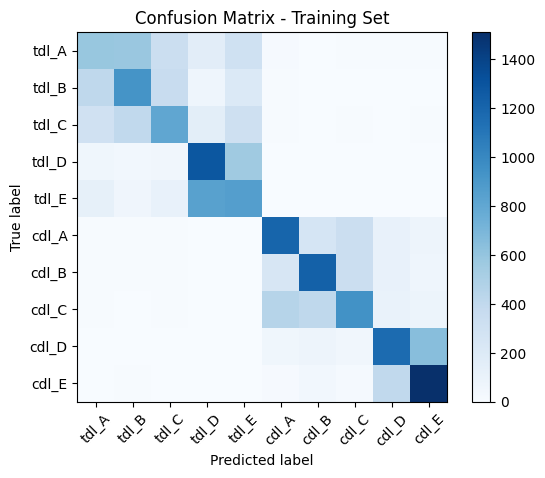

Confusion Matrix:
[[ 585  582  332  157  306   14    4    7    6    7]
 [ 411  928  359   67  212   10    3    3    3    4]
 [ 300  401  805  152  315    6    1    8    3    9]
 [  54   43   52 1286  560    4    1    0    0    0]
 [ 125   63  107  842  860    2    1    0    0    0]
 [   8    9    7    0    0 1204  255  332  113   72]
 [  11    7    9    0    0  237 1226  331  113   66]
 [   8    2    8    0    0  450  412  939  104   77]
 [   3    2    2    0    0   55   73   50 1166  649]
 [   2    6    1    0    0   17   42   23  398 1511]]


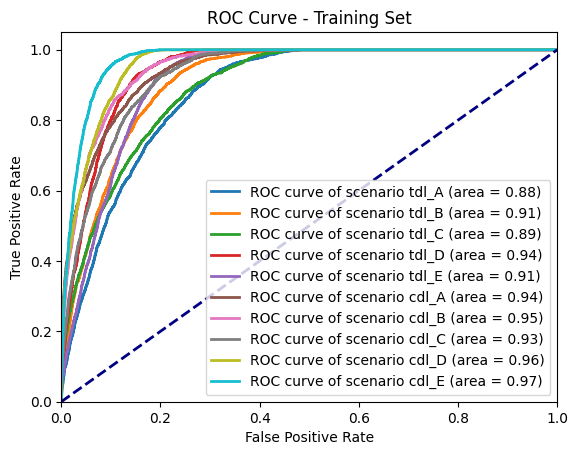

Metrics for Training Set:
Accuracy: 0.5255
Precision: 0.5223
Recall: 0.5255
F1 Score: 0.5211
ROC AUC: 0.9287
Log Loss: 1.0630


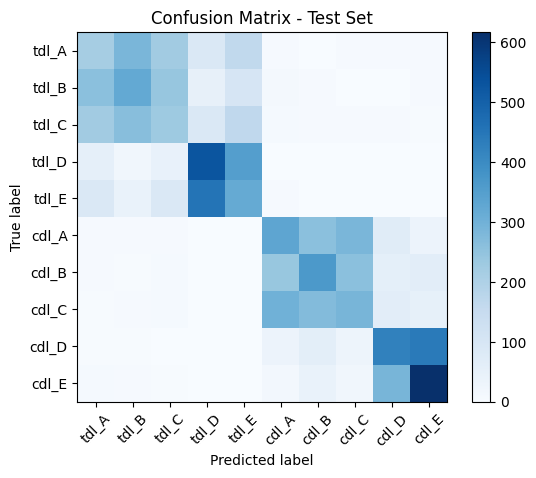

Confusion Matrix:
[[215 286 222  89 162   6   2   7   6   5]
 [258 322 242  49 103  10   6   2   2   6]
 [224 263 229  88 166   8   7   6   5   4]
 [ 55  21  45 528 350   1   0   0   0   0]
 [ 88  42  89 455 320   5   0   0   0   1]
 [  7   6   5   0   0 332 258 286  70  36]
 [  5   4   8   0   0 239 364 259  57  64]
 [  4   7   9   1   1 301 272 289  64  52]
 [  4   4   2   0   1  36  61  30 422 440]
 [  8   5   4   0   0  16  41  21 288 617]]


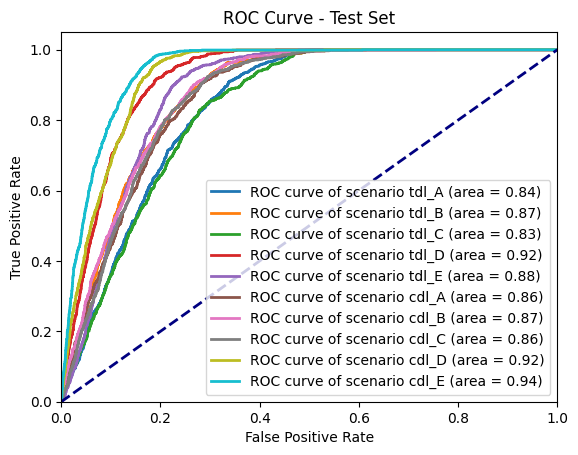

Metrics for Test Set:
Accuracy: 0.3638
Precision: 0.3572
Recall: 0.3638
F1 Score: 0.3589
ROC AUC: 0.8799
Log Loss: 1.4725


In [5]:
# import numpy as np
# import matplotlib.pyplot as plt
# from sklearn.metrics import confusion_matrix, roc_curve, auc
# from sklearn.preprocessing import label_binarize
# Load the checkpoint mlp_checkpoints/mlp_model_epoch_1000.h5 for the model
model = tf.keras.models.load_model('mlp_checkpoints/mlp_model_epoch_1000.h5')

class_labels = df_full["model_type"] + "_" + df_full["scenario"].astype(str)
X_train = features
y_train = labels
X_test = features_test
y_test = labels_test
class_labels = class_labels.unique()
y_train_pred = model.predict(X_train).argmax(axis=1)
y_train_prob = model.predict(X_train)

y_test_pred = model.predict(X_test).argmax(axis=1)
y_test_prob = model.predict(X_test)
# def plot_roc_curve_multiclass(y_true, y_prob, classes, title='ROC Curve'):
#     # Binarize the output
#     y_true_bin = label_binarize(y_true, classes=range(len(classes)))
#     print(y_true_bin)
#     n_classes = y_true_bin.shape[1]
#     # Compute ROC curve and ROC area for each class
#     fpr = dict()
#     tpr = dict()
#     roc_auc = dict()
#     for i in range(n_classes):
#         fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
#         roc_auc[i] = auc(fpr[i], tpr[i])

#     # Plot ROC curve for each class
#     plt.figure()
#     for i in range(n_classes):
#         plt.plot(fpr[i], tpr[i], lw=2, label=f'ROC curve of scenario {classes[i]} (area = {roc_auc[i]:0.2f})')
#     plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
#     plt.xlim([0.0, 1.0])
#     plt.ylim([0.0, 1.05])
#     plt.xlabel('False Positive Rate')
#     plt.ylabel('True Positive Rate')
#     plt.title(title)
#     plt.legend(loc="lower right")
#     plt.show()
# Plot confusion matrix and ROC curve for training semulticlass(y_train, y_train_pred, title='Confusion Matrix - Training Set')
plot_confusion_matrix_multiclass(y_train, y_train_pred, class_labels, title='Confusion Matrix - Training Set')
plot_roc_curve_multiclass(y_train, y_train_prob, class_labels,title='ROC Curve - Training Set')

# Print metrics for training set
print("Metrics for Training Set:")
print_metrics_multiclass(y_train, y_train_pred, y_train_prob)


# Plot confusion matrix and ROC curve for test set

class_labels = df_full_test["model_type"] + "_" + df_full_test["scenario"].astype(str)
class_labels = class_labels.unique()
plot_confusion_matrix_multiclass(y_test, y_test_pred, class_labels, title='Confusion Matrix - Test Set')
plot_roc_curve_multiclass(y_test, y_test_prob, class_labels, title='ROC Curve - Test Set')

# Print metrics for test set
print("Metrics for Test Set:")
print_metrics_multiclass(y_test, y_test_pred, y_test_prob)


TDL Dataset NLOS/LOS Classification
=======================================

In [ ]:
# Train the model and get predictions
features_tdl, labels_tdl = preprocess_data_channel(df_tdl)
features_tdl_test, labels_tdl_test = preprocess_data_channel(df_tdl_test)

y_tdl_train, y_tdl_train_pred, y_tdl_train_prob, y_tdl_test, y_tdl_test_pred, y_tdl_test_prob = train_mlp_channel(features_tdl, labels_tdl, features_tdl_test, labels_tdl_test, model_name='mlp_model_tdl.keras')

# Plot confusion matrix and ROC curve for tdl training set
class_labels = df_tdl["scenario"].astype(str)
class_labels = class_labels.unique()
plot_confusion_matrix_multiclass(y_tdl_train, y_tdl_train_pred, class_labels, title='Confusion Matrix - TDL Training Set')
plot_roc_curve_multiclass(y_tdl_train, y_tdl_train_prob, class_labels, title='ROC Curve - TDL Training Set')
# Print metrics for tdl training set
print("Metrics for TDL Training Set:")
print_metrics_multiclass(y_tdl_train, y_tdl_train_pred, y_tdl_train_prob)

# Plot confusion matrix and ROC curve for tdl test set
class_labels = df_tdl_test["scenario"].astype(str)
class_labels = class_labels.unique()
plot_confusion_matrix_multiclass(y_tdl_test, y_tdl_test_pred, class_labels, title='Confusion Matrix - TDL Test Set')
plot_roc_curve_multiclass(y_tdl_test, y_tdl_test_prob, class_labels, title='ROC Curve - TDL Test Set')

# Print metrics for tdl test set
print("Metrics for TDL Test Set:")
print_metrics_multiclass(y_tdl_test, y_tdl_test_pred, y_tdl_test_prob)

CDL Dataset NLOS/LOS Classification
=======================================

In [ ]:
features_cdl, labels_cdl = preprocess_data_channel(df_cdl)
features_cdl_test, labels_cdl_test = preprocess_data_channel(df_cdl_test)

y_cdl_train, y_cdl_train_pred, y_cdl_train_prob, y_cdl_test, y_cdl_test_pred, y_cdl_test_prob = train_mlp_channel(features_cdl, labels_cdl, features_cdl_test, labels_cdl_test, model_name='mlp_model_cdl.keras')

# Plot confusion matrix and ROC curve for cdl training set
class_labels = df_cdl["scenario"].astype(str)
class_labels = class_labels.unique()
plot_confusion_matrix_multiclass(y_cdl_train, y_cdl_train_pred, class_labels, title='Confusion Matrix - CDL Training Set')
plot_roc_curve_multiclass(y_cdl_train, y_cdl_train_prob, class_labels, title='ROC Curve - CDL Training Set')

# Print metrics for cdl training set
print("Metrics for CDL Training Set:")
print_metrics_multiclass(y_cdl_train, y_cdl_train_pred, y_cdl_train_prob)

# Plot confusion matrix and ROC curve for cdl test set
plot_confusion_matrix_multiclass(y_cdl_test, y_cdl_test_pred, class_labels, title='Confusion Matrix - CDL Test Set')
plot_roc_curve_multiclass(y_cdl_test, y_cdl_test_prob, class_labels, title='ROC Curve - CDL Test Set')

# Print metrics for cdl test set
print("Metrics for CDL Test Set:")
print_metrics_multiclass(y_cdl_test, y_cdl_test_pred, y_cdl_test_prob)


SIONNA MIMO Dataset NLOS/LOS Classification
=======================================

In [ ]:
# # Train the model and get predictions
# features_sionna_mimo, labels_sionna_mimo = preprocess_data_channel(df_sionna_mimo)
# features_sionna_mimo_test, labels_sionna_mimo_test = preprocess_data_channel(df_sionna_mimo_test)

# y_sionna_mimo_train, y_sionna_mimo_train_pred, y_sionna_mimo_train_prob, y_sionna_mimo_test, y_sionna_mimo_test_pred, y_sionna_mimo_test_prob = train_mlp_channel(features_sionna_mimo, labels_sionna_mimo, features_sionna_mimo_test, labels_sionna_mimo_test, model_name='mlp_model_sionna_mimo.keras')
# # Plot confusion matrix and ROC curve for sionna mimo training set
# class_labels = df_sionna_mimo["scenario"].astype(str)
# class_labels = class_labels.unique()
# plot_confusion_matrix_multiclass(y_sionna_mimo_train, y_sionna_mimo_train_pred, class_labels, title='Confusion Matrix - Sionna MIMO Training Set')
# plot_roc_curve_multiclass(y_sionna_mimo_train, y_sionna_mimo_train_prob, class_labels, title='ROC Curve - Sionna MIMO Training Set')

# # Print metrics for sionna mimo training set
# print("Metrics for Sionna MIMO Training Set:")
# plot_confusion_matrix_multiclass(y_sionna_mimo_train, y_sionna_mimo_train_pred, class_labels, title='Confusion Matrix - Sionna MIMO Training Set')
# plot_roc_curve_multiclass(y_sionna_mimo_train, y_sionna_mimo_train_prob, class_labels, title='ROC Curve - Sionna MIMO Training Set')

# # Plot confusion matrix and ROC curve for sionna mimo test set
# plot_confusion_matrix_multiclass(y_sionna_mimo_test, y_sionna_mimo_test_pred, class_labels, title='Confusion Matrix - Sionna MIMO Test Set')
# plot_roc_curve_multiclass(y_sionna_mimo_test, y_sionna_mimo_test_prob, class_labels, title='ROC Curve - Sionna MIMO Test Set')

# # Print metrics for sionna mimo test set
# print("Metrics for Sionna MIMO Test Set:")
# print_metrics_multiclass(y_sionna_mimo_test, y_sionna_mimo_test_pred, y_sionna_mimo_test_prob)

SIONNA SISO Dataset NLOS/LOS Classification
=======================================

In [ ]:
# # Load the datasets
# df_siso = pd.read_csv("dataset_sionna_siso.csv")

# # Combine the datasets
# df = df_siso
# # take 80 percent of the data for training, 20 percent for testing
# features, labels = preprocess_data_channel(df.sample(frac=0.8))
# features_test, labels_test = preprocess_data_channel(df.sample(frac=0.2))
# # Train the model and get predictions
# y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_mlp_channel(features, labels, features_test, labels_test, model_name='mlp_model_siso.keras')

# # Plot confusion matrix and ROC curve for training set
# class_labels = df["scenario"].astype(str)
# class_labels = class_labels.unique()
# plot_confusion_matrix_multiclass(y_train, y_train_pred, class_labels, title='Confusion Matrix - Training Set')
# plot_roc_curve_multiclass(y_train, y_train_prob, class_labels, title='ROC Curve - Training Set')


# # Print metrics for training set
# print("Metrics for Training Set:")
# print_metrics_multiclass(y_train, y_train_pred, y_train_prob)

# # Plot confusion matrix and ROC curve for test set
# class_labels = df["scenario"].astype(str)
# class_labels = class_labels.unique()
# plot_confusion_matrix_multiclass(y_test, y_test_pred, class_labels, title='Confusion Matrix - Test Set')
# plot_roc_curve_multiclass(y_test, y_test_prob, class_labels, title='ROC Curve - Test Set')

# # Print metrics for test set
# print("Metrics for Test Set:")
# print_metrics_multiclass(y_test, y_test_pred, y_test_prob)